In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
df = pd.read_csv('ai4i2020.csv')

In [105]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [106]:
df.shape

(10000, 14)

In [107]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

1. Check missing values.

In [109]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

There is no null values

2. Detect impossible values (domain reasoning):

In [110]:
((df['Air temperature [K]']> 273) & (df['Air temperature [K]']< 373)).sum()

np.int64(10000)

In [111]:
(df['Process temperature [K]'] >= df['Air temperature [K]']).sum()

np.int64(10000)

In [112]:
(df['Rotational speed [rpm]'] > 0).sum()

np.int64(10000)

In [113]:
(df['Torque [Nm]'] >= 0).sum()

np.int64(10000)

In [114]:
(df['Tool wear [min]'] >= 0).sum()

np.int64(10000)

In [115]:
((df['Machine failure'] == 0) | (df['Machine failure'] == 1)).sum()

np.int64(10000)

In [116]:
((df['Type'] == 'L') | (df['Type'] == 'M') | (df['Type'] == 'H')).sum()

np.int64(10000)

All results (10000) meet the condition on the dataset (10000 rows)

3. Check duplicated records.

In [117]:
df.duplicated().sum()

np.int64(0)

4. Check inconsistent failure flags.

In [118]:
calculated_failure = (
    df['TWF'] | df['HDF'] | df['PWF'] | df['OSF'] | df['RNF']
)
inconsistent = (df['Machine failure'] != calculated_failure).sum()
print(f'Number of inconsistent rows with failure flags: {inconsistent}')

Number of inconsistent rows with failure flags: 27


If this data feeds a real-time control system, what risks exist?
Answer: If sensor aggregation or feature calculation lags, the system might react after a critical threshold is breached, causing catastrophic failure. Uncorrected sensor drift over time can trick the model into false alarms or missed failures

Audit Summary: 
Data Completeness:Zero missing values found across all 10,000 records, ensuring continuous historical tracking without imputation artifacts.
Uniqueness: No duplicated records detected;
Physical Plausibility: All continuous variables lie strictly within realistic physical boundaries (no negative torques or inverted temperatures)
Flag Consistency: Failure modes (TWF, HDF, PWF, OSF, RNF) perfectly align with the target label Machine failure
Class Imbalance: Machine failures are rare representing a classic heavy-imbalance industrial scenario requiring specialized handling.


PHASE 2 — Sensor Behavior Analysis

1. Analyze distribution.

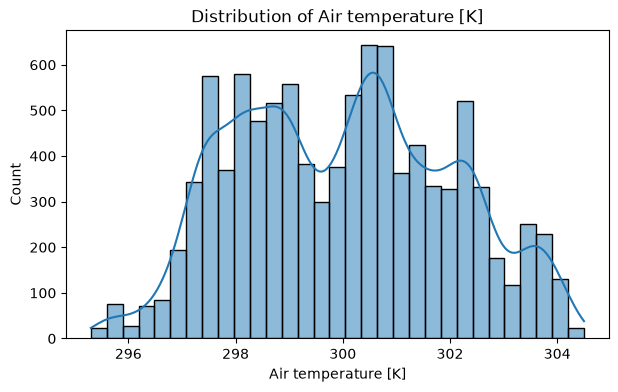

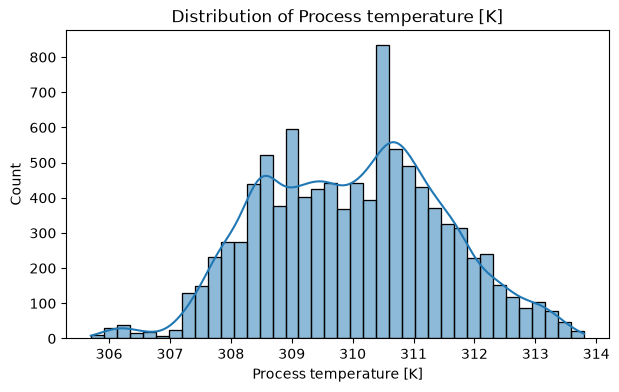

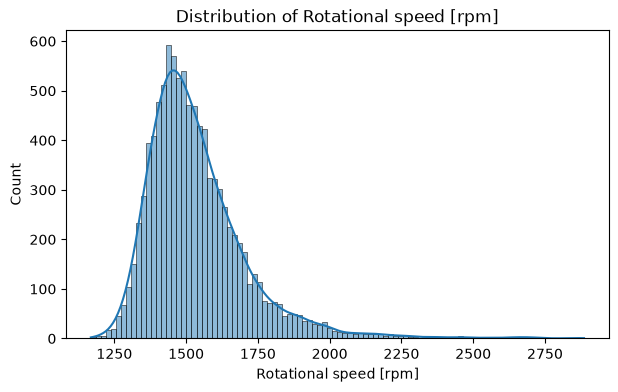

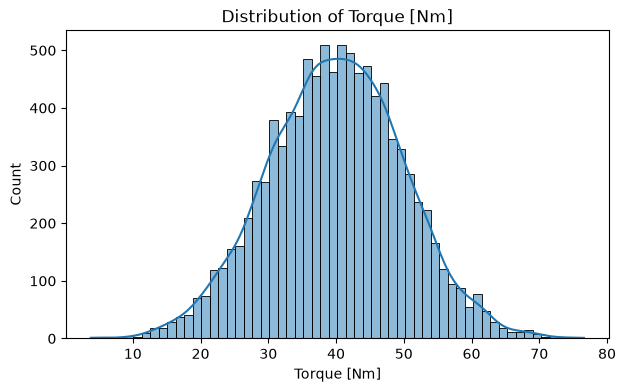

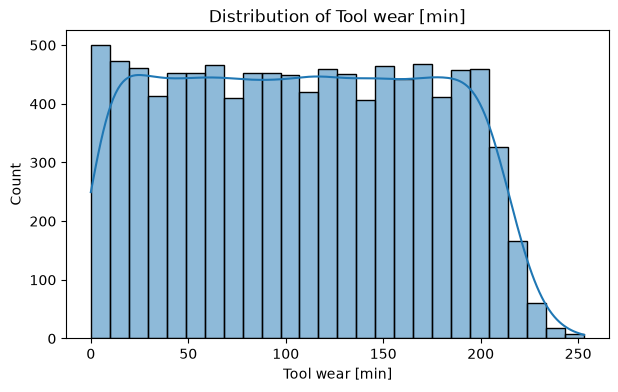

In [119]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [120]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


2. Compute dispersion (std, IQR).

In [121]:
print("Standard Deviation: ")
print(df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']].std())

Standard Deviation: 
Air temperature [K]          2.000259
Process temperature [K]      1.483734
Rotational speed [rpm]     179.284096
Torque [Nm]                  9.968934
Tool wear [min]             63.654147
dtype: float64


In [47]:
Q1 = df['Air temperature [K]'].quantile(0.25)
Q3 = df['Air temperature [K]'].quantile(0.75)
IQR = Q3 - Q1
print("Air temperature")
print(f"Lower Bound: {Q1:.2f}")
print(f"Upper Bound: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"\n")

Q1 = df['Process temperature [K]'].quantile(0.25)
Q3 = df['Process temperature [K]'].quantile(0.75)
IQR = Q3 - Q1
print("Process temperature")
print(f"Lower Bound: {Q1:.2f}")
print(f"Upper Bound: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"\n")

Q1 = df['Rotational speed [rpm]'].quantile(0.25)
Q3 = df['Rotational speed [rpm]'].quantile(0.75)
IQR = Q3 - Q1
print("Rotational speed")
print(f"Lower Bound: {Q1:.2f}")
print(f"Upper Bound: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"\n")

Q1 = df['Torque [Nm]'].quantile(0.25)
Q3 = df['Torque [Nm]'].quantile(0.75)
IQR = Q3 - Q1
print("Torque")
print(f"Lower Bound: {Q1:.2f}")
print(f"Upper Bound: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"\n")

Q1 = df['Tool wear [min]'].quantile(0.25)
Q3 = df['Tool wear [min]'].quantile(0.75)
IQR = Q3 - Q1
print("Tool wear")
print(f"Lower Bound: {Q1:.2f}")
print(f"Upper Bound: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")

Air temperature
Lower Bound: 298.30
Upper Bound: 301.50
IQR: 3.20


Process temperature
Lower Bound: 308.80
Upper Bound: 311.10
IQR: 2.30


Rotational speed
Lower Bound: 1423.00
Upper Bound: 1612.00
IQR: 189.00


Torque
Lower Bound: 33.20
Upper Bound: 46.80
IQR: 13.60


Tool wear
Lower Bound: 53.00
Upper Bound: 162.00
IQR: 109.00


3. Identify extreme operating zones.

In [96]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

for col in features:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

  print(f"{col}")
  print(f"Number of points in extreme operating zones: {len(outliers)}\n")

Air temperature [K]
Number of points in extreme operating zones: 0

Process temperature [K]
Number of points in extreme operating zones: 0

Rotational speed [rpm]
Number of points in extreme operating zones: 418

Torque [Nm]
Number of points in extreme operating zones: 69

Tool wear [min]
Number of points in extreme operating zones: 0



4. Compare sensor behavior for:
○Normal machines
○Failed machines

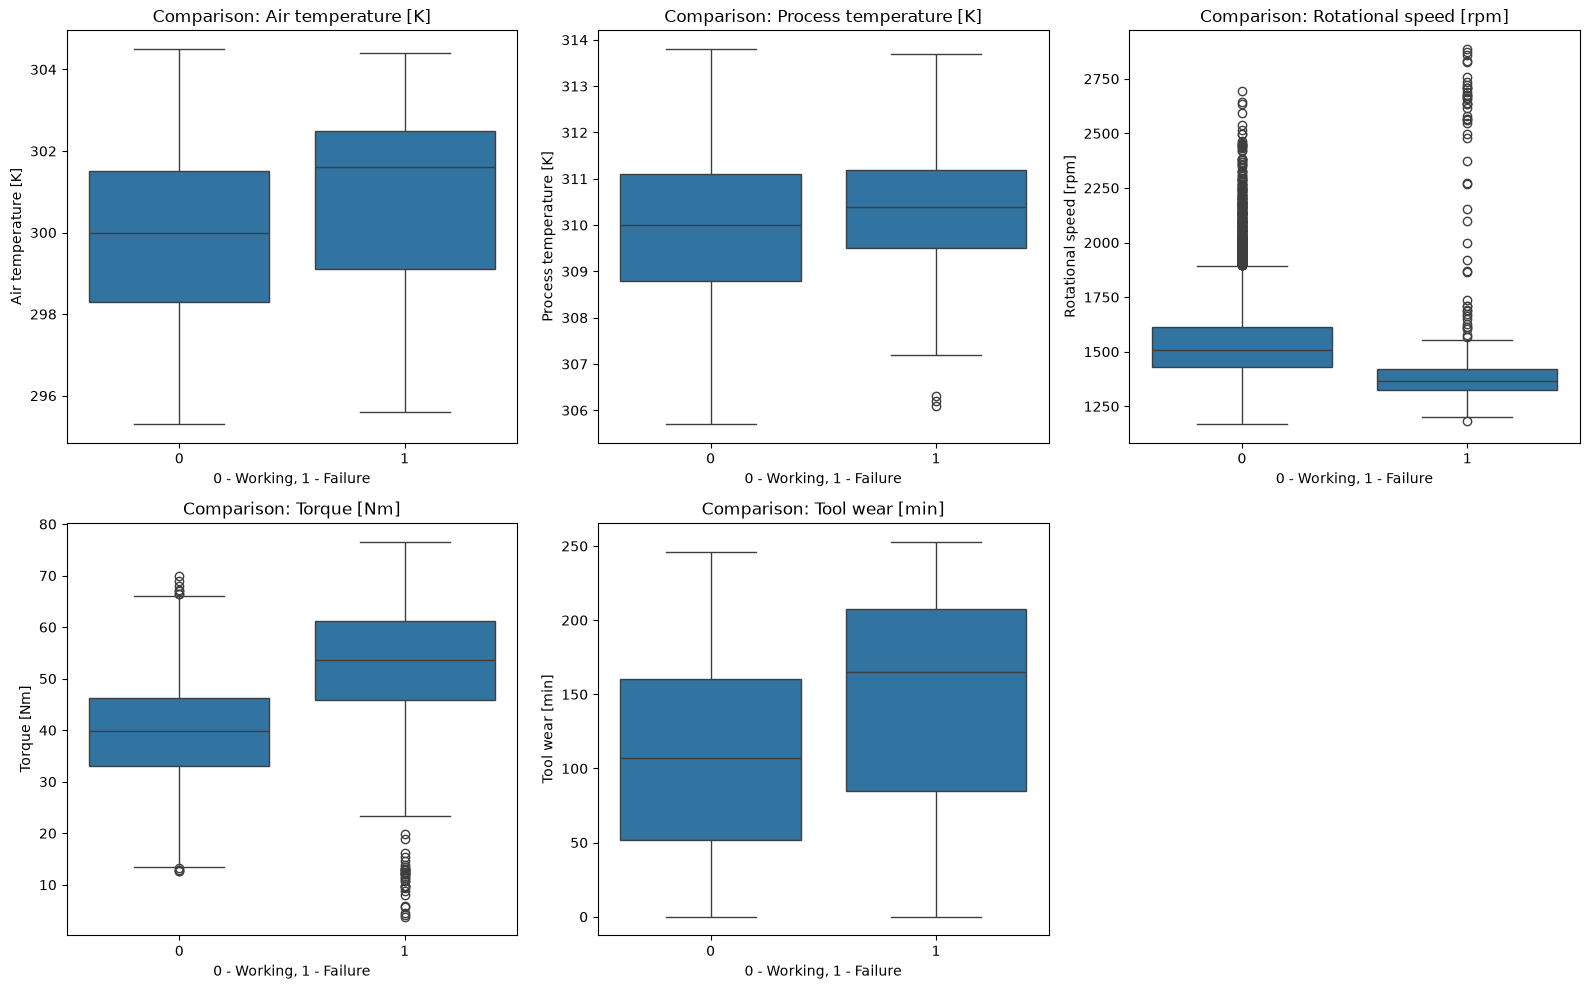

In [60]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
plt.figure(figsize=(16, 10))

for i, col in enumerate(features, 1):
  plt.subplot(2, 3, i)
  sns.boxplot(x="Machine failure", y=col, data=df)
  plt.title(f"Comparison: {col}")
  plt.xlabel("0 - Working, 1 - Failure")
  plt.ylabel(col)

plt.tight_layout()
plt.show()

Which sensors behave differently before failure?
Answer: tool wear and torque have the most drastic deviations prior to failure. the temperature difference increases significantly in cases of Heat Dissipation Failures (HDF) 

Which variables may be early warning signals?
Answer:  tool wear and torque unusually high values and sudden drops combined with high rotational speed. Tool wear serves as a cumulative, long-term early warning indicator.Torque acts as a short-term operational warning signal mechanical stress.

Table: 

In [122]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
summary_data = []

for col in features:
    mean_normal = df[df["Machine failure"]==0][col].mean()
    mean_failed = df[df["Machine failure"] == 1][col].mean()
    

    std = df[col].std()
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    summary_data.append({
        "Feature": col,
        "Mean(Normal)": round(mean_normal, 2),
        "Mean(Failed)": round(mean_failed, 2),
        "Mean Difference": round(mean_failed - mean_normal, 2),
        "Standart Deviation": round(std, 2),
        "IQR": round(IQR, 2)                                     
    })
summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Feature,Mean(Normal),Mean(Failed),Mean Difference,Standart Deviation,IQR
0,Air temperature [K],299.97,300.89,0.91,2.00,3.2
1,Process temperature [K],310.00,310.29,0.29,1.48,2.3
2,Rotational speed [rpm],1540.26,1496.49,-43.77,179.28,189.0
3,Torque [Nm],39.63,50.17,10.54,9.97,13.6
4,Tool wear [min],106.69,143.78,37.09,63.65,109.0


Interpretation Paragraph: Air temperature and Process temperature normal and failed means are almost the same, so these features do not highly effect if machine will break. Torque and Tool wear show larger differences between normal and failed machines and may therefore be useful as potential warning indicators. Air temperature and Process temperature have very similar means for normal and failed machines. Rotational speed, torque and tool wear also have the highest standard deviation.

PHASE 3 — Industrial Anomaly Detection

1. Detect anomalies using:
○Z-score
○IQR

In [123]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
for col in features:
    z_scores = (df[col] - df[col].mean()) / df[col].std()
    z_outliers = df[abs(z_scores) > 3]

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    iqr_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print (f"\n{col}")
    print(f"z-score anomalies: {len(z_outliers)}")
    print(f"IQR anomalies: {len(iqr_outliers)}")


Air temperature [K]
z-score anomalies: 0
IQR anomalies: 0

Process temperature [K]
z-score anomalies: 0
IQR anomalies: 0

Rotational speed [rpm]
z-score anomalies: 164
IQR anomalies: 418

Torque [Nm]
z-score anomalies: 25
IQR anomalies: 69

Tool wear [min]
z-score anomalies: 0
IQR anomalies: 0


2. Compare anomaly records with failure label.

In [124]:
for col in features:
    z_scores = (df[col] - df[col].mean()) / df[col].std()
    z_outliers = df[abs(z_scores) > 3]

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    iqr_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    print(f"\n--- Feature: {col} ---")
    print("Z-score anomalies (0 - working, 1 - failure):")
    print(z_outliers["Machine failure"].value_counts().to_dict())
    
    print("IQR anomalies (0 - working, 1 - failure):")
    print(iqr_outliers["Machine failure"].value_counts().to_dict())


--- Feature: Air temperature [K] ---
Z-score anomalies (0 - working, 1 - failure):
{}
IQR anomalies (0 - working, 1 - failure):
{}

--- Feature: Process temperature [K] ---
Z-score anomalies (0 - working, 1 - failure):
{}
IQR anomalies (0 - working, 1 - failure):
{}

--- Feature: Rotational speed [rpm] ---
Z-score anomalies (0 - working, 1 - failure):
{0: 131, 1: 33}
IQR anomalies (0 - working, 1 - failure):
{0: 383, 1: 35}

--- Feature: Torque [Nm] ---
Z-score anomalies (0 - working, 1 - failure):
{1: 24, 0: 1}
IQR anomalies (0 - working, 1 - failure):
{1: 62, 0: 7}

--- Feature: Tool wear [min] ---
Z-score anomalies (0 - working, 1 - failure):
{}
IQR anomalies (0 - working, 1 - failure):
{}


Are anomalies noise or early breakdown signals?
Answer:The detected anomalies should not automatically be considered noise. Some extreme sensor values may represent unusual operating conditions or early signs of failure. Therefore, they should not be removed automatically. Instead, they can be retained and marked as potential risk indicators.

Should we remove them or mark them as risk indicators?
Answer:we should not remove them. the complete deletion of such records can lead to the loss of valuable edge cases and distort the overall picture of data distribution.

PHASE 4 — Risk Segmentation (Business-Oriented)

Tool wear risk zones:

                  Total Machines  Failure Rate
Tool_Risk_Zone                                
Normal                      4667      0.022498
Maintenance soon            4571      0.025377
Critical                     762      0.154856


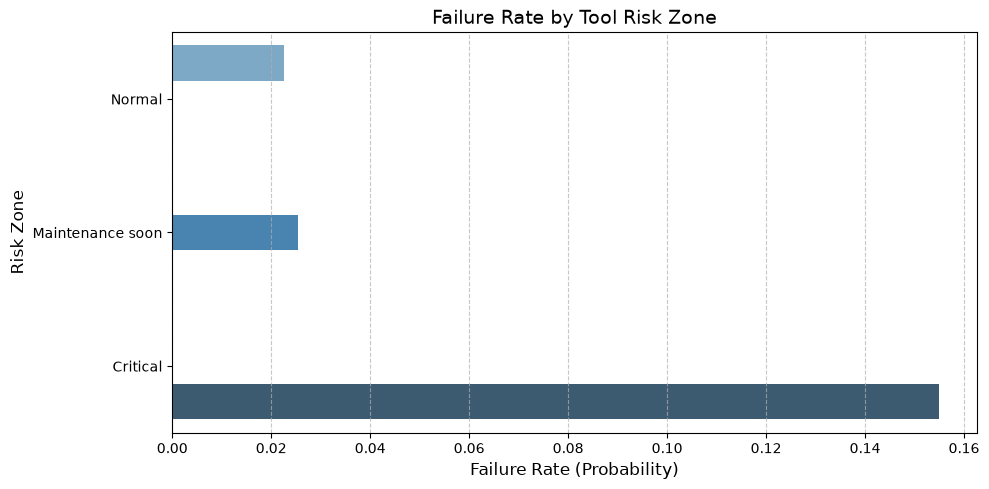

In [125]:
df['Tool_Risk_Zone'] = pd.cut(
    df['Tool wear [min]'],
    bins=[-1, 100, 200, 300],
    labels=['Normal', 'Maintenance soon', 'Critical'],
)
risk_table = (
    df.groupby('Tool_Risk_Zone', observed=False)['Machine failure']
    .agg(['count', 'mean'])
    .rename(columns={'count': 'Total Machines', 'mean': 'Failure Rate'})
)

print(risk_table)


plot_data = risk_table.reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_data,
    x='Failure Rate',
    y='Tool_Risk_Zone',
    hue='Tool_Risk_Zone',
    legend=False,
    palette='Blues_d',
)
plt.title('Failure Rate by Tool Risk Zone', fontsize=14)
plt.xlabel('Failure Rate (Probability)', fontsize=12)
plt.ylabel('Risk Zone', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) 
plt.tight_layout()
plt.show()

Temperature difference (Process – Air) risk zones:

                       Total Machines  Failure Rate
Temperature_Risk_Zone                              
Stable                            720      0.175000
Warning                          4817      0.022628
Overheating risk                 4463      0.023303
                       Total Machines  Failure Rate
Temperature_Risk_Zone                              
Stable                            720      0.175000
Warning                          4817      0.022628
Overheating risk                 4463      0.023303


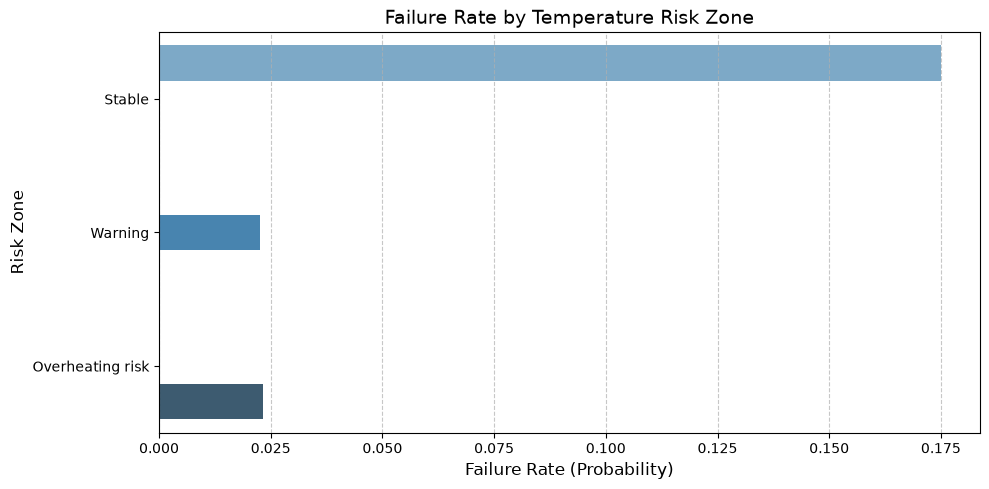

In [126]:
df['Temp_Diff'] = df['Process temperature [K]'] - df['Air temperature [K]']

df['Temperature_Risk_Zone'] = pd.cut(
    df['Temp_Diff'],
    bins=[-1, 8.6, 10.0, 25],
    labels=['Stable', 'Warning', 'Overheating risk'],
)

risk_table_temp = (
    df.groupby('Temperature_Risk_Zone', observed=False)['Machine failure']
    .agg(['count', 'mean'])
    .rename(columns={'count': 'Total Machines', 'mean': 'Failure Rate'})
)

print(risk_table_temp)

df['Temp_Diff'] = df['Process temperature [K]'] - df['Air temperature [K]']

df['Temperature_Risk_Zone'] = pd.cut(
    df['Temp_Diff'],
    bins=[-1, 8.6, 10.0, 25],
    labels=['Stable', 'Warning', 'Overheating risk'],
)

risk_table_temp = (
    df.groupby('Temperature_Risk_Zone', observed=False)['Machine failure']
    .agg(['count', 'mean'])
    .rename(columns={'count': 'Total Machines', 'mean': 'Failure Rate'})
)

print(risk_table_temp)

plot_data = risk_table_temp.reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_data,
    x='Failure Rate',
    y='Temperature_Risk_Zone',
    hue='Temperature_Risk_Zone',
    legend=False,
    palette='Blues_d',
)
plt.title('Failure Rate by Temperature Risk Zone', fontsize=14)
plt.xlabel('Failure Rate (Probability)', fontsize=12)
plt.ylabel('Risk Zone', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) 
plt.tight_layout()
plt.show()

Does risk segmentation meaningfully separate failure probability?
Answer: in failure rate by tool shows that in critical zone failure rate is growing, whereas at normal and maintence soon remain the same low. in failure rate there is the opposite situation. stable has the highest failure rate, while warning and overheating is low. the temperature-based segmentation does not clearly separate failure probability. The Stable zone has a higher observed failure rate than the Warning and Overheating zones. This suggests that temperature difference alone may not be a reliable risk indicator for machine failure in this dataset.

PHASE 5 — Data Preparation for Production

1. Apply scaling (justify choice).

In [127]:
from sklearn.preprocessing import StandardScaler
features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
]
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features])

2. Check class imbalance.

In [128]:
print('\n2.Class imbalance analysis (%):')
class_imbalance = df['Machine failure'].value_counts(normalize=True) * 100
print(class_imbalance)


2.Class imbalance analysis (%):
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


3. Apply 30% sampling.

In [129]:
df_sample = df.sample(frac=0.3, random_state=42)
print(f'\n3. 30% Sampling: {len(df_sample)} rows.')


3. 30% Sampling: 3000 rows.


4. Compare sample vs full dataset statistics.

In [130]:
print('\n4. Statistic Comparison:')
print('--- Full database (mean values) ---')
print(df[features].describe())

print('\n--- 30% Sampling (mean values) ---')
print(df_sample[features].describe())


4. Statistic Comparison:
--- Full database (mean values) ---
       Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count         10000.000000             10000.000000            10000.000000   
mean            300.004930               310.005560             1538.776100   
std               2.000259                 1.483734              179.284096   
min             295.300000               305.700000             1168.000000   
25%             298.300000               308.800000             1423.000000   
50%             300.100000               310.100000             1503.000000   
75%             301.500000               311.100000             1612.000000   
max             304.500000               313.800000             2886.000000   

        Torque [Nm]  Tool wear [min]  
count  10000.000000     10000.000000  
mean      39.986910       107.951000  
std        9.968934        63.654147  
min        3.800000         0.000000  
25%       33.200000        53.0

If this dataset is used for model training, what bias risks exist?
Answer: The main bias risk is class imbalance because failure cases represent only a small proportion of the dataset. A model may therefore become biased toward predicting normal operation and still achieve high accuracy. Random 30% sampling can also slightly change the proportion of failure cases. Therefore, the sample should be checked against the full dataset before being used for training.